# Basic EDA: USDA Cropland Data Layer — Maryland

This notebook examines the CDL crop and land-cover classes within Maryland. It uses the official Census TIGERweb state boundary to clip the local CDL GeoTIFFs, then calculates class counts from the full-resolution pixels inside the state.

The earlier nationwide percentage was approximate because it used a downsampled national raster. Maryland summaries below use full-resolution pixels. The large CDL rasters remain local and are not included in Git.

In [1]:
from pathlib import Path
import re

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests
from matplotlib.colors import ListedColormap
from rasterio.mask import mask as mask_raster

candidates = [Path.cwd(), Path.cwd() / "notebooks" / "dataset"]
DATA_DIR = next(
    (path for path in candidates if list(path.glob("CDL_*/*_30m_cdls.tif"))),
    candidates[-1],
)
cdl_files = sorted(DATA_DIR.glob("CDL_*/*_30m_cdls.tif"))
if not cdl_files:
    raise FileNotFoundError(f"No CDL GeoTIFFs found under {DATA_DIR}")

def get_year(path):
    match = re.search(r"(\d{4})_30m_cdls\.tif$", path.name)
    return int(match.group(1)) if match else None

years = [get_year(path) for path in cdl_files]
years

[2023]

In [2]:
# Fetch Maryland's state outline from the official Census TIGERweb service.
# The response is requested in EPSG:5070, matching the local CDL raster.
boundary_url = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/MapServer/0/query"
response = requests.get(
    boundary_url,
    params={"where": "STATE='24'", "outFields": "NAME,STATE", "outSR": "5070", "f": "geojson"},
    timeout=60,
)
response.raise_for_status()
boundary_data = response.json()
maryland = gpd.GeoDataFrame.from_features(boundary_data["features"], crs="EPSG:5070")
if len(maryland) != 1 or maryland.iloc[0]["NAME"] != "Maryland":
    raise ValueError("Census TIGERweb did not return exactly one Maryland state boundary")
maryland_geom = maryland.geometry.iloc[0]
pd.Series({
    "state": maryland.iloc[0]["NAME"],
    "state FIPS": maryland.iloc[0]["STATE"],
    "boundary CRS": maryland.crs.to_string(),
    "valid geometry": maryland_geom.is_valid,
    "empty geometry": maryland_geom.is_empty,
})

state              Maryland
state FIPS               24
boundary CRS      EPSG:5070
valid geometry         True
empty geometry        False
dtype: object

In [3]:
# Clip each available CDL year to Maryland and count full-resolution classes.
year_counts = {}
metadata_rows = []
latest_year = max(years)
maryland_raster = None
maryland_transform = None

for path in cdl_files:
    year = get_year(path)
    with rasterio.open(path) as src:
        state_boundary = maryland.to_crs(src.crs)
        clipped, clipped_transform = mask_raster(
            src, [state_boundary.geometry.iloc[0]], crop=True, filled=False
        )
        state_pixels = clipped[0]
        valid = ~np.ma.getmaskarray(state_pixels)
        values = state_pixels.data[valid]
        counts = np.bincount(values.astype(np.uint8), minlength=256)
        year_counts[year] = counts
        metadata_rows.append({
            "year": year,
            "file": path.name,
            "size (GB)": round(path.stat().st_size / 1e9, 2),
            "width": src.width,
            "height": src.height,
            "CRS": src.crs.to_string(),
            "resolution (m)": src.res,
            "dtype": src.dtypes[0],
            "NoData value": src.nodata,
            "mask flags": [flag.name for flag in src.mask_flag_enums[0]],
            "Maryland crop shape": state_pixels.shape,
            "valid Maryland pixels": int(valid.sum()),
            "cloud/no-data class 81 pixels": int(counts[81]),
        })
        if year == latest_year:
            maryland_raster = state_pixels
            maryland_transform = clipped_transform

metadata = pd.DataFrame(metadata_rows).set_index("year").sort_index()
metadata

,file,size (GB),width,height,CRS,resolution (m),dtype,NoData value,mask flags,Maryland crop shape,valid Maryland pixels,cloud/no-data class 81 pixels
year,,,,,,,,,,,,
2023,2023_30m_cdls.tif,3.34,153811,96523,EPSG:5070,"(30.0, 30.0)",uint8,None,[all_valid],"(6976, 13536)",35701264,0


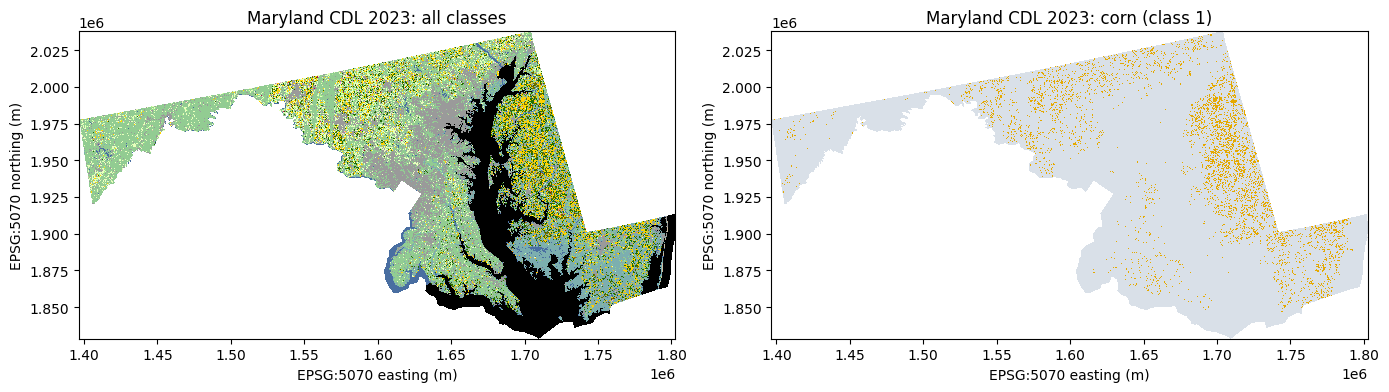

In [4]:
# Plot Maryland's CDL classes and a corn-only view for the latest available year.
with rasterio.open(next(path for path in cdl_files if get_year(path) == latest_year)) as src:
    palette = src.colormap(1)
    colors = [
        tuple(channel / 255 for channel in palette.get(i, (0, 0, 0, 255)))
        for i in range(256)
    ]

rows, cols = maryland_raster.shape
left = maryland_transform.c
top = maryland_transform.f
right = left + maryland_transform.a * cols
bottom = top + maryland_transform.e * rows
extent = (left, right, bottom, top)
masked_classes = np.ma.masked_array(maryland_raster.data, mask=np.ma.getmaskarray(maryland_raster))
corn_mask = np.ma.masked_array(
    (maryland_raster.data == 1).astype(np.uint8),
    mask=np.ma.getmaskarray(maryland_raster),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(masked_classes, cmap=ListedColormap(colors), vmin=0, vmax=255, extent=extent, interpolation="nearest")
axes[0].set_title(f"Maryland CDL {latest_year}: all classes")
axes[1].imshow(corn_mask, cmap=ListedColormap(["#d9e0e8", "#e5a900"]), vmin=0, vmax=1, extent=extent, interpolation="nearest")
axes[1].set_title(f"Maryland CDL {latest_year}: corn (class 1)")
for ax in axes:
    ax.set_xlabel("EPSG:5070 easting (m)")
    ax.set_ylabel("EPSG:5070 northing (m)")
fig.tight_layout()

In [5]:
# Summarize all CDL classes and the most common crop categories in Maryland.
class_names = {
    0: "Background", 1: "Corn", 2: "Cotton", 3: "Rice", 4: "Sorghum",
    5: "Soybeans", 6: "Sunflower", 10: "Peanuts", 12: "Sweet corn",
    13: "Popcorn", 21: "Barley", 22: "Durum wheat", 23: "Spring wheat",
    24: "Winter wheat", 26: "Winter wheat/soybeans", 36: "Alfalfa",
    37: "Other hay", 41: "Sugarbeets", 48: "Watermelons",
    59: "Sod/grass seed", 61: "Fallow/idle cropland",
    81: "Clouds/no data", 82: "Developed", 83: "Water", 87: "Wetlands",
    88: "Nonag/undefined", 111: "Open water", 121: "Developed/open space",
    122: "Developed/low intensity", 123: "Developed/medium intensity",
    124: "Developed/high intensity", 141: "Deciduous forest",
    228: "Double crop triticale/corn", 254: "Double crop barley/soybeans",
    142: "Evergreen forest", 143: "Mixed forest", 152: "Shrubland",
    176: "Grassland/pasture", 190: "Woody wetlands", 195: "Herbaceous wetlands",
}
crop_codes = set(range(1, 62)) | set(range(66, 78)) | set(range(204, 251)) | {254}
counts = year_counts[latest_year]
class_distribution = pd.DataFrame([
    {
        "class code": code,
        "class name": class_names.get(code, f"CDL class {code}"),
        "pixels": int(counts[code]),
        "percent of Maryland": 100 * counts[code] / metadata.loc[latest_year, "valid Maryland pixels"],
    }
    for code in np.flatnonzero(counts)
]).sort_values("pixels", ascending=False)

top_classes = class_distribution.head(15)
top_crop_classes = class_distribution[class_distribution["class code"].isin(crop_codes)].head(12)
top_classes

,class code,class name,pixels,percent of Maryland
44,141,Deciduous forest,7300131,20.447822
0,0,Background,6947061,19.458866
49,190,Woody wetlands,3419770,9.578849
39,121,Developed/open space,2575126,7.212983
48,176,Grassland/pasture,2465754,6.906629
1,1,Corn,2354558,6.595167
3,5,Soybeans,1867427,5.230703
46,143,Mixed forest,1719044,4.815079
40,122,Developed/low intensity,1683256,4.714836
38,111,Open water,941133,2.636134


,class code,class name,pixels,percent of Maryland
1,1,Corn,2354558,6.595167
3,5,Soybeans,1867427,5.230703
16,37,Other hay,722860,2.024746
10,26,Winter wheat/soybeans,610899,1.711141
73,254,Double crop barley/soybeans,60913,0.170619
15,36,Alfalfa,51986,0.145614
2,4,Sorghum,47711,0.133640
29,59,Sod/grass seed,38621,0.108178
9,24,Winter wheat,33477,0.093770
62,228,Double crop triticale/corn,20845,0.058387


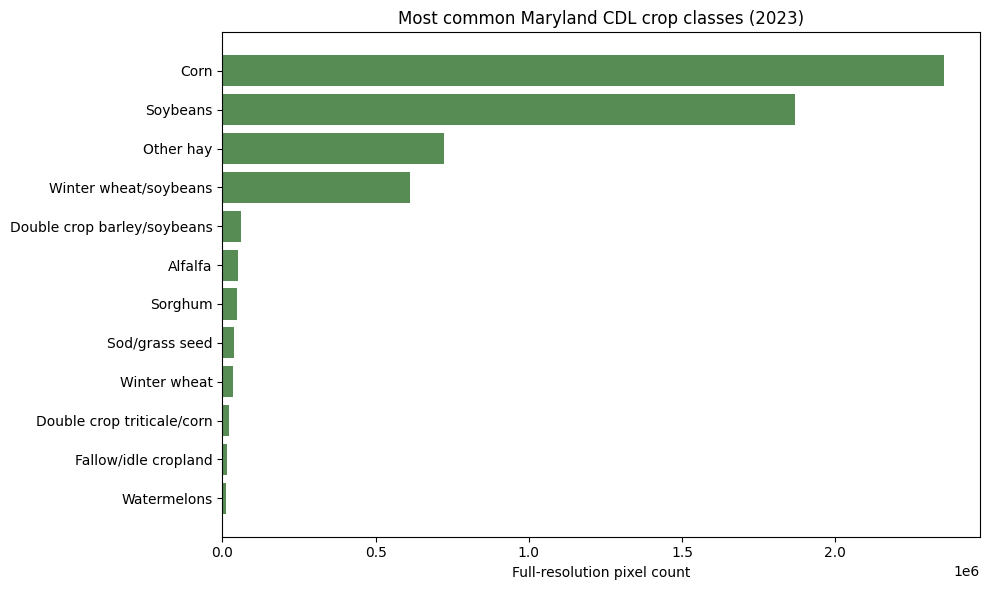

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_crop_classes["class name"][::-1], top_crop_classes["pixels"][::-1], color="#578c55")
ax.set_title(f"Most common Maryland CDL crop classes ({latest_year})")
ax.set_xlabel("Full-resolution pixel count")
fig.tight_layout()
top_crop_classes[["class code", "class name", "pixels", "percent of Maryland"]]

,Maryland corn pixels,Maryland valid pixels,corn percent
year,,,
2023,2354558,35701264,6.595


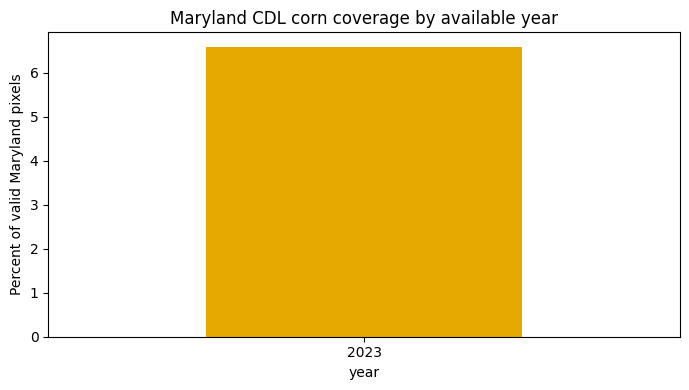

In [7]:
# Compare corn's share of Maryland pixels across locally available CDL years.
year_comparison = pd.DataFrame([
    {
        "year": year,
        "Maryland corn pixels": int(counts[1]),
        "Maryland valid pixels": int(counts.sum()),
        "corn percent": 100 * counts[1] / counts.sum(),
    }
    for year, counts in sorted(year_counts.items())
]).set_index("year")
display(year_comparison.round(3))
year_comparison["corn percent"].plot(kind="bar", color="#e5a900", legend=False, figsize=(7, 4))
plt.ylabel("Percent of valid Maryland pixels")
plt.title("Maryland CDL corn coverage by available year")
plt.xticks(rotation=0)
plt.tight_layout()

## Interpretation notes

- Class percentages and maps are for Maryland only and use the full-resolution pixels inside the state boundary.
- The GeoTIFF has no NoData value and uses an all-valid raster mask. CDL class 0 (`Background`) is a category, not missing data; the class-81 `Clouds/No Data` count is reported separately.
- The available files determine which years can be compared. With only one local CDL year, the notebook reports that year's Maryland distribution but cannot show a temporal trend.
- Corn is represented by CDL class 1 and is summarized as one crop category.